<a href="https://colab.research.google.com/github/farahmandzohreh9-netizen/Zora/blob/main/ADTA_5230_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ZF10_ADTA 5230 Final Project_ Spring 2026_8 Week 2



In [1]:
# version https://git-lfs.github.com/spec/v1

In [6]:
import pandas as pd

df_turnover = pd.read_excel('/content/sample_data/TAPR 2023 Report. Final 3.xlsx')
display(df_turnover.head())

,DISTRICT,DISTNAME,TEA Description,DPFEIERP,DPSAINHP,DPSAMIFC,DPSAMIFP,DPSATOFC,DPSBTOFC,DPSBTOPC,...,DPSTWHFC,DPSTWHFP,DPSUTOFC,DPSUTOFP,DPSUTOSA,DPSXCOFC,DPSXTOFC,DPSXTOFP,TEA Description2,TEA Description3
0,'001902,CAYUGA ISD,Rural,57,71.3,12.8,12.5,102,0,1,...,46.5,96,6.4,6.2,57090,2.1,25.6,25.1,Rural,NaN
1,'001903,ELKHART ISD,Non-metropolitan Stable,61.5,68.8,25,13.2,189,0,0,...,93.5,89.5,9.9,5.2,60509,0,36.5,19.3,Non-metropolitan Stable,NaN
2,'001904,FRANKSTON ISD,Rural,54.4,61.5,16.7,11.8,141.7,0,0,...,64,94.1,2.7,1.9,59435,0,40.7,28.7,Rural,NaN
3,'001906,NECHES ISD,Rural,54.9,58.8,11.7,18.8,62.2,0,0,...,27.1,96.6,2,3.2,66243,0,14.6,23.4,Rural,NaN
4,'001907,PALESTINE ISD,Independent Town,57.4,70.3,193.9,34.5,561.6,0,0,...,182.4,72.6,48.2,8.6,66404,0,114.1,20.3,Independent Town,NaN


In [7]:
df_turnover.isnull()

,DISTRICT,DISTNAME,TEA Description,DPFEIERP,DPSAINHP,DPSAMIFC,DPSAMIFP,DPSATOFC,DPSBTOFC,DPSBTOPC,...,DPSTWHFC,DPSTWHFP,DPSUTOFC,DPSUTOFP,DPSUTOSA,DPSXCOFC,DPSXTOFC,DPSXTOFP,TEA Description2,TEA Description3
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1204,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1205,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1206,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
1207,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True


In [8]:
missing_values_count = df_turnover.isnull().sum()
display(missing_values_count)

,0
DISTRICT,0
DISTNAME,0
TEA Description,0
DPFEIERP,0
DPSAINHP,0
...,...
DPSXCOFC,0
DPSXTOFC,0
DPSXTOFP,0
TEA Description2,0


Missing: 102 rows × 1 columns

In [9]:
(df_turnover.isnull().mean()) * 100

,0
DISTRICT,0.0
DISTNAME,0.0
TEA Description,0.0
DPFEIERP,0.0
DPSAINHP,0.0
...,...
DPSXCOFC,0.0
DPSXTOFC,0.0
DPSXTOFP,0.0
TEA Description2,0.0


<Axes: >

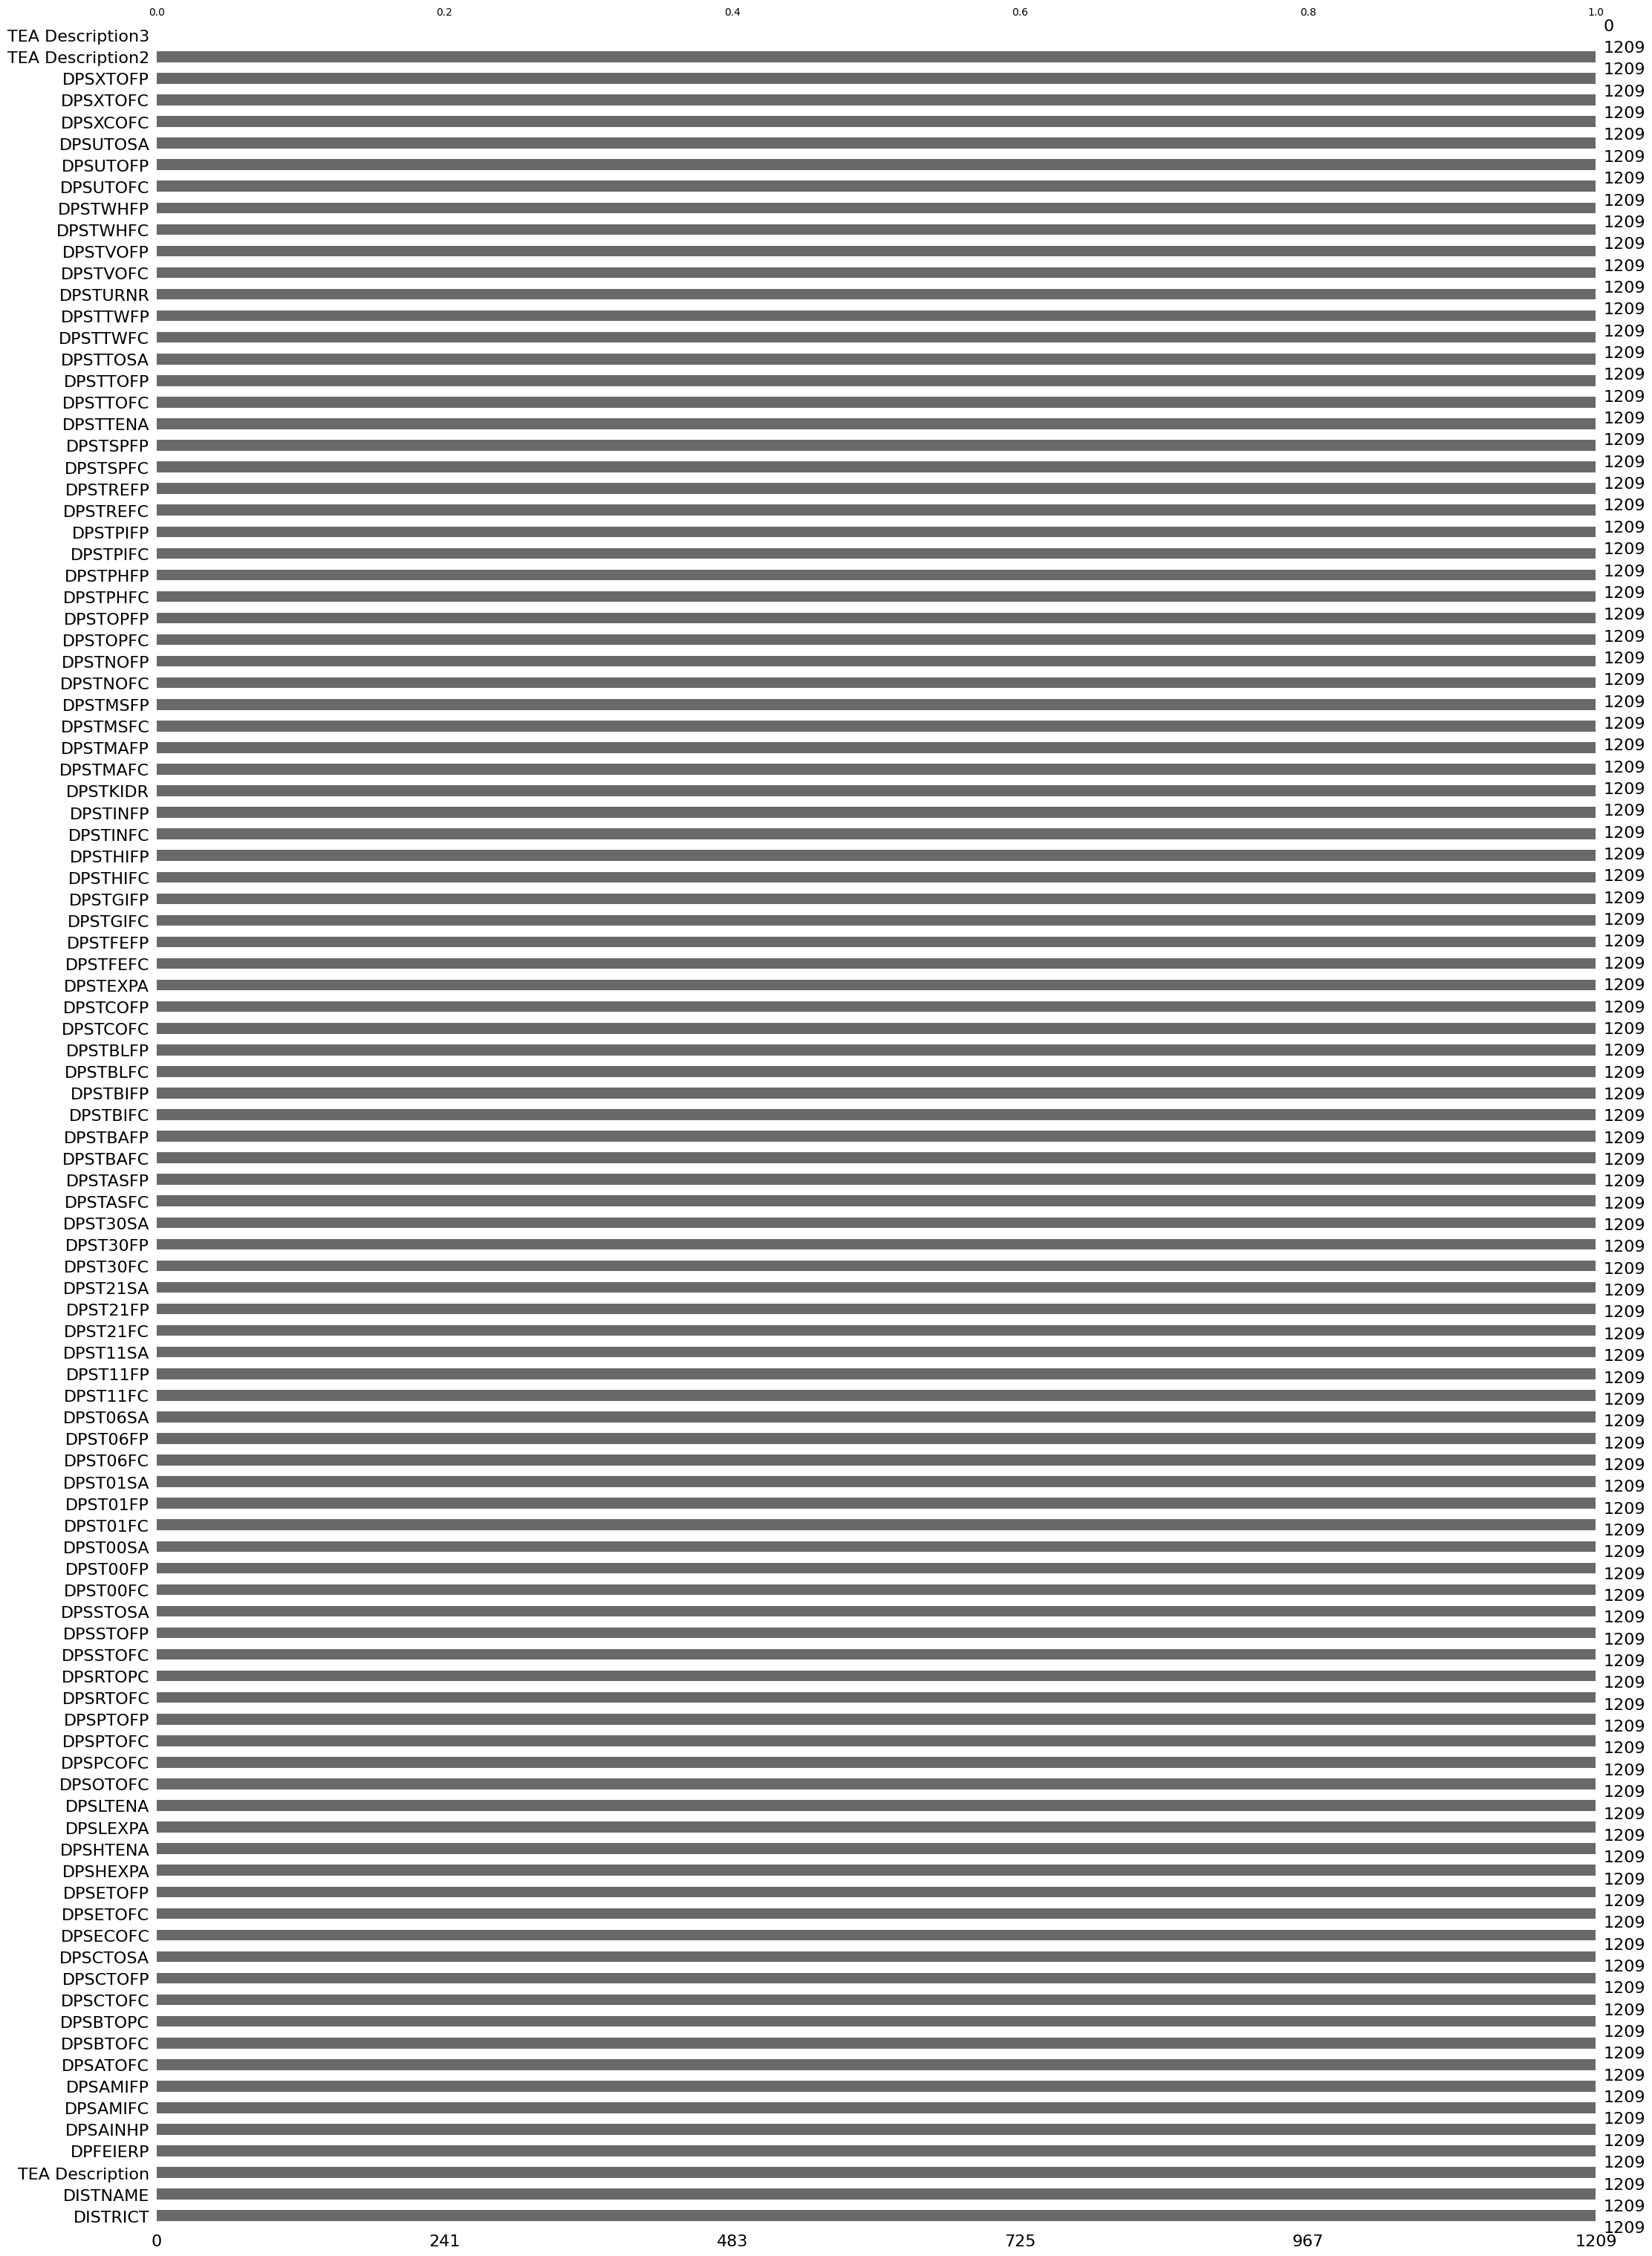

In [10]:
import missingno as msno
msno.bar(df_turnover)

In [12]:
import numpy as np

# Select only numeric columns
numeric_df = df_turnover.select_dtypes(include=np.number)

# Compute Z-scores
z_scores = (numeric_df - numeric_df.mean()) / numeric_df.std()

# Find outliers (threshold = 3)
outliers = (np.abs(z_scores) > 3)

# Count outliers per column
outlier_counts = outliers.sum()

print(outlier_counts.sort_values(ascending=False))

TEA Description3    0
dtype: int64


No outliers were found

In [13]:
# Show only columns with invalid values
numeric_df = df_turnover.select_dtypes(include=np.number)
# Count negative values in each column
invalid_negatives = (numeric_df < 0).sum()

# Show only columns with invalid values
print(invalid_negatives[invalid_negatives > 0])

Series([], dtype: int64)


In [14]:
# Find duplicate ISDs based on District Name
duplicates = df_turnover[df_turnover.duplicated(subset='DISTNAME', keep=False)]
#Verify is duplicates are removed
print("Duplicate ISDs:")
print(duplicates)
print("Number of duplicate rows:", df_turnover.duplicated(subset='DISTNAME').sum())
duplicate_names = df_turnover['DISTNAME'][df_turnover.duplicated(subset='DISTNAME')]
print(duplicate_names)
#identify duplicates
df_clean = df_turnover.drop_duplicates(subset='DISTNAME', keep=False)
#Remove all the duplicates
print("Remaining duplicates:", df_clean.duplicated(subset='DISTNAME').sum())

Duplicate ISDs:
     DISTRICT           DISTNAME              TEA Description DPFEIERP  \
81    '015905       EDGEWOOD ISD               Major Suburban     58.5   
91    '015915      NORTHSIDE ISD                  Major Urban     66.2   
116   '019913        HUBBARD ISD                        Rural     67.9   
192   '039905         MIDWAY ISD                        Rural     61.5   
212   '043914          WYLIE ISD  Other Central City Suburban     66.4   
231   '049903    VALLEY VIEW ISD      Non-metropolitan Stable     54.2   
290   '057911  HIGHLAND PARK ISD               Major Suburban     66.7   
297   '058902         DAWSON ISD                        Rural     45.1   
590   '108916    VALLEY VIEW ISD  Other Central City Suburban       60   
595   '109905        HUBBARD ISD                        Rural     53.1   
741   '145902    CENTERVILLE ISD                        Rural     61.6   
796   '161903         MIDWAY ISD  Other Central City Suburban     64.1   
866   '175904         

In [15]:
#Finding rare categories
rare_summary = {}

for col in df_turnover.select_dtypes(include='object').columns:
    freq = df_turnover[col].value_counts(normalize=True)
    rare = freq[freq < 0.05]

    if len(rare) > 0:
        rare_summary[col] = rare

# Print results
for col, values in rare_summary.items():
    print(f"\nColumn: {col}")
    print(values)


Column: DISTRICT
DISTRICT
'254902    0.000827
'001902    0.000827
'001903    0.000827
'001904    0.000827
'001906    0.000827
             ...   
'003906    0.000827
'003905    0.000827
'003904    0.000827
'003903    0.000827
'003902    0.000827
Name: proportion, Length: 1209, dtype: float64

Column: DISTNAME
DISTNAME
HUBBARD ISD                0.001654
EDGEWOOD ISD               0.001654
MIDWAY ISD                 0.001654
VALLEY VIEW ISD            0.001654
BIG SANDY ISD              0.001654
                             ...   
LAMAR CISD                 0.000827
CROWELL ISD                0.000827
LOCKNEY ISD                0.000827
FLOYDADA COLLEGIATE ISD    0.000827
TEAGUE ISD                 0.000827
Name: proportion, Length: 1198, dtype: float64

Column: TEA Description
TEA Description
Independent Town                 0.043838
Other Central City               0.028950
Non-metropolitan Fast Growing    0.028122
Major Urban                      0.009098
Name: proportion, dtype: fl

In [16]:
import pandas as pd

# Shape (rows, columns)
df_turnover.shape

# First rows
df_turnover.head()

# Data types + missing values
df_turnover.info()

df_turnover.describe(include='all')


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1209 entries, 0 to 1208
Columns: 102 entries, DISTRICT to TEA Description3
dtypes: float64(1), object(101)
memory usage: 963.6+ KB


,DISTRICT,DISTNAME,TEA Description,DPFEIERP,DPSAINHP,DPSAMIFC,DPSAMIFP,DPSATOFC,DPSBTOFC,DPSBTOPC,...,DPSTWHFC,DPSTWHFP,DPSUTOFC,DPSUTOFP,DPSUTOSA,DPSXCOFC,DPSXTOFC,DPSXTOFP,TEA Description2,TEA Description3
count,1209,1209,1209,1209.0,1209.0,1209.0,1209.0,1209.0,1209.0,1209.0,...,1209.0,1209.0,1209.0,1209.0,1209,1209.0,1209.0,1209.0,1209,0.0
unique,1209,1198,9,257.0,287.0,806.0,622.0,1077.0,56.0,17.0,...,843.0,541.0,543.0,188.0,1126,52.0,781.0,299.0,9,NaN
top,'254902,HUBBARD ISD,Rural,60.0,62.9,2.0,0.0,67.3,0.0,0.0,...,0.0,100.0,0.0,0.0,.,0.0,1.0,26.8,Rural,NaN
freq,1,2,464,18.0,16.0,19.0,10.0,4.0,750.0,932.0,...,19.0,58.0,60.0,57.0,60,1065.0,12.0,15.0,464,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
df_turnover['DPSTEXPA'] = pd.to_numeric(df_turnover['DPSTEXPA'], errors='coerce')

# Display the data types to confirm the change
print(df_turnover['DPSTEXPA'].dtype)

# Display the first few rows of the modified column to see the effect
display(df_turnover[['DPSTEXPA']].head())

float64


,DPSTEXPA
0,14.5
1,13.1
2,11.3
3,15.9
4,12.4


Now that the `DPSTEXPA` column has been converted to a numeric type, you can perform mean, median, and standard deviation calculations without errors.

In [18]:
df_turnover['DPSTEXPA'].mean()
df_turnover['DPSTEXPA'].median()
df_turnover['DPSTEXPA'].std()

3.497261914589505

In [19]:
print(f"Mean of DPSTEXPA: {df_turnover['DPSTEXPA'].mean()}")
print(f"Median of DPSTEXPA: {df_turnover['DPSTEXPA'].median()}")
print(f"Standard Deviation of DPSTEXPA: {df_turnover['DPSTEXPA'].std()}")

Mean of DPSTEXPA: 11.55771144278607
Median of DPSTEXPA: 11.8
Standard Deviation of DPSTEXPA: 3.497261914589505


In [20]:
df_turnover['DPSTTOSA'] = pd.to_numeric(df_turnover['DPSTTOSA'], errors='coerce')

print(f"Mean of DPSTTOSA: {df_turnover['DPSTTOSA'].mean()}")
print(f"Median of DPSTTOSA: {df_turnover['DPSTTOSA'].median()}")
print(f"Standard Deviation of DPSTTOSA: {df_turnover['DPSTTOSA'].std()}")

Mean of DPSTTOSA: 55562.98589211618
Median of DPSTTOSA: 54908.0
Standard Deviation of DPSTTOSA: 5583.265272546291


In [21]:
df_turnover['DPSTKIDR'] = pd.to_numeric(df_turnover['DPSTKIDR'], errors='coerce')

print(f"Mean of DPSTKIDR: {df_turnover['DPSTKIDR'].mean()}")
print(f"Median of DPSTKIDR: {df_turnover['DPSTKIDR'].median()}")
print(f"Standard Deviation of DPSTKIDR: {df_turnover['DPSTKIDR'].std()}")

Mean of DPSTKIDR: 12.707296849087895
Median of DPSTKIDR: 12.8
Standard Deviation of DPSTKIDR: 3.2288065171337705


In [22]:
import pandas as pd
df_turnover['DPSTURNR'] = pd.to_numeric(df_turnover['DPSTURNR'], errors='coerce')

print(f"Mean of DPSTURNR: {df_turnover['DPSTURNR'].mean()}")
print(f"Median of TURNR: {df_turnover['DPSTURNR'].median()}")
print(f"Standard Deviation of DPSTURNR: {df_turnover['DPSTURNR'].std()}")

Mean of DPSTURNR: 25.086011656952543
Median of TURNR: 23.2
Standard Deviation of DPSTURNR: 11.866527328155614


In [40]:
counts = df_turnover['TEA Description'].value_counts()
percent = df_turnover['TEA Description'].value_counts(normalize=True) * 100

summary = pd.DataFrame({
    'Count': counts,
    'Percent': percent
})

print(summary)
df_turnover['TEA Description'].mode()

                               Count    Percent
TEA Description                                
Rural                            464  38.378825
Charter Schools                  188  15.550041
Non-metropolitan Stable          181  14.971050
Other Central City Suburban      168  13.895782
Major Suburban                    75   6.203474
Independent Town                  53   4.383788
Other Central City                35   2.894955
Non-metropolitan Fast Growing     34   2.812242
Major Urban                       11   0.909843


,TEA Description
0,Rural


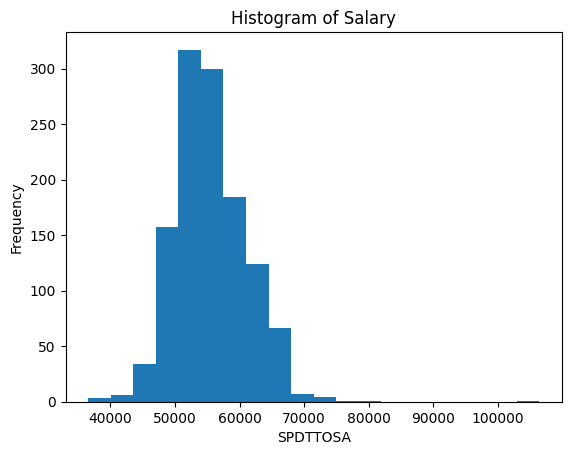

In [28]:
#Salary Histogram
import matplotlib.pyplot as plt

data = df_turnover['DPSTTOSA'].dropna()

plt.hist(data, bins=20)
plt.xlabel('SPDTTOSA')
plt.ylabel('Frequency')
plt.title('Histogram of Salary')
plt.show()

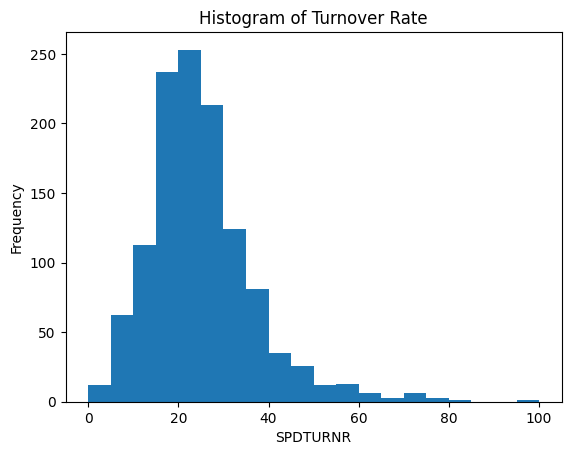

In [30]:
#Turnover histogram
Data = df_turnover['DPSTURNR'].dropna()

plt.hist(data, bins=20)
plt.xlabel('SPDTURNR')
plt.ylabel('Frequency')
plt.title('Histogram of Turnover Rate')
plt.show()

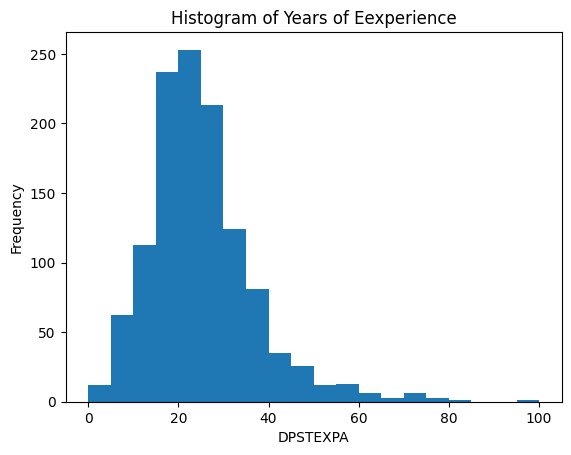

In [34]:
#Years of experience histogram
Data = df_turnover['DPSTEXPA'].dropna()

plt.hist(data, bins=20)
plt.xlabel('DPSTEXPA')
plt.ylabel('Frequency')
plt.title('Histogram of Years of Eexperience')
plt.show()

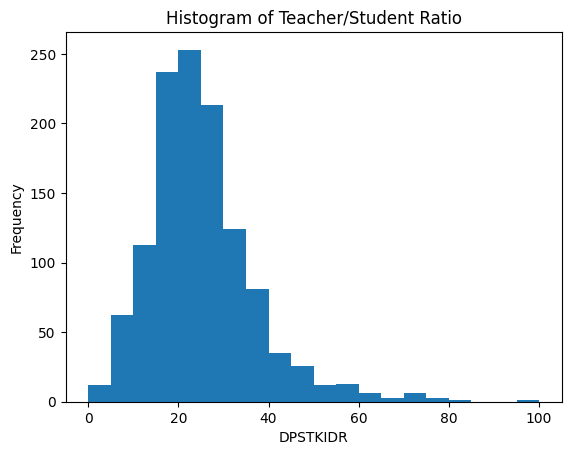

In [36]:
Data = df_turnover['DPSTKIDR'].dropna()

plt.hist(data, bins=20)
plt.xlabel('DPSTKIDR')
plt.ylabel('Frequency')
plt.title('Histogram of Teacher/Student Ratio')
plt.show()

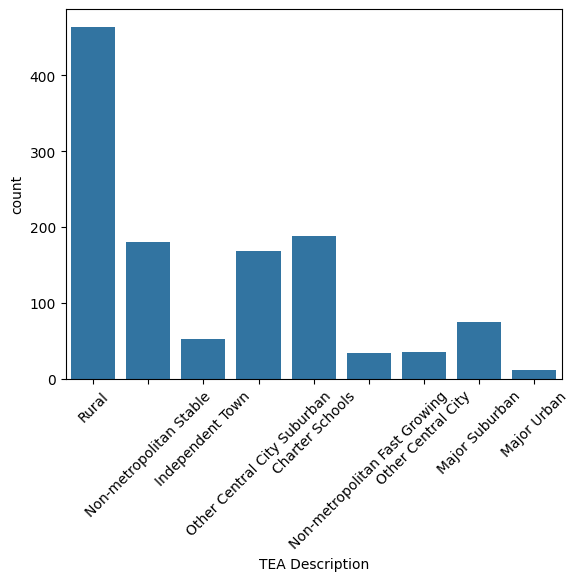

In [38]:
sns.countplot(x='TEA Description', data=df_turnover            )

plt.xticks(rotation=45)   # rotate labels
plt.show()

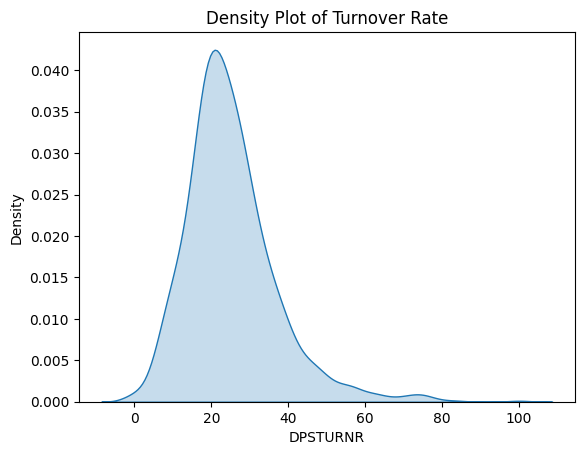

In [31]:
import seaborn as sns

data = df_turnover['DPSTURNR'].dropna()

sns.kdeplot(data, fill= True)
plt.title('Density Plot of Turnover Rate')
plt.xlabel('DPSTURNR')
plt.ylabel('Density')
plt.show()

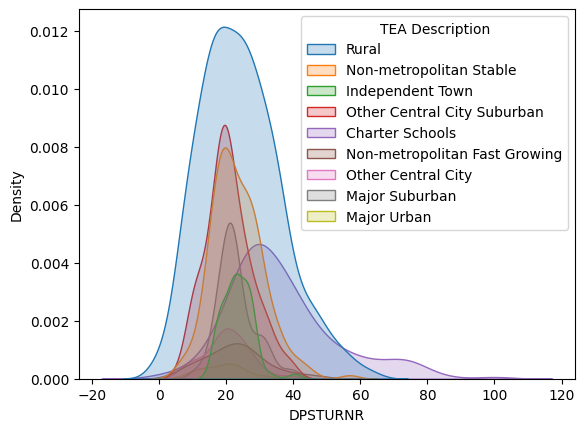

In [33]:
sns.kdeplot(data=df_turnover, x='DPSTURNR', hue='TEA Description', fill=True)
plt.show()

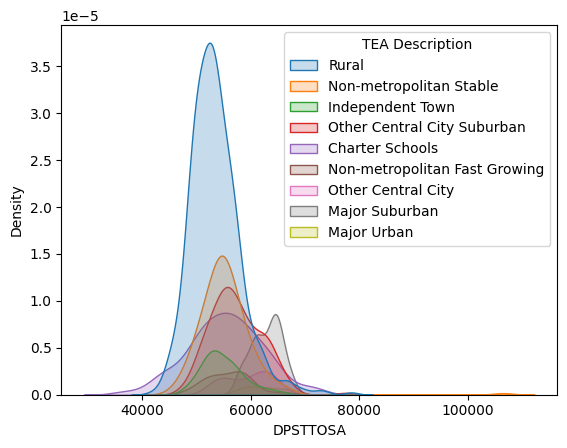

In [41]:
sns.kdeplot(data=df_turnover, x='DPSTTOSA', hue='TEA Description', fill=True)
plt.show()

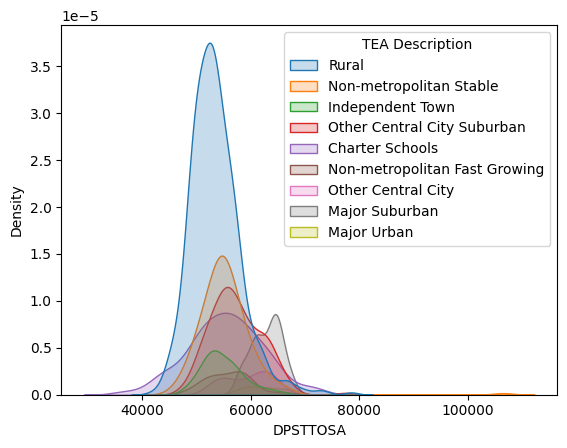

In [43]:
sns.kdeplot(data=df_turnover, x='DPSTTOSA', hue='TEA Description', fill=True)
plt.show()

In [44]:
df_turnover[['DPSTURNR', 'DPSTTOSA', 'DPSTEXPA', 'DPSTKIDR']].corr()

,DPSTURNR,DPSTTOSA,DPSTEXPA,DPSTKIDR
DPSTURNR,1.000000,-0.188463,-0.493263,0.120449
DPSTTOSA,-0.188463,1.000000,0.051316,0.293131
DPSTEXPA,-0.493263,0.051316,1.000000,-0.290463
DPSTKIDR,0.120449,0.293131,-0.290463,1.000000


In [47]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr

cols = ['DPSTURNR', 'DPSTTOSA', 'DPSTEXPA', 'DPSTKIDR']

# Create a temporary DataFrame with only the relevant columns and drop rows with NaN values
df_filtered = df_turnover[cols].dropna()

# Empty matrices
corr_matrix = pd.DataFrame(index=cols, columns=cols)
p_matrix = pd.DataFrame(index=cols, columns=cols)

# Loop through variables
for i in cols:
    for j in cols:
        r, p = pearsonr(df_filtered[i], df_filtered[j])
        corr_matrix.loc[i, j] = r
        p_matrix.loc[i, j] = p

print("Correlation Matrix:")
print(corr_matrix)

print("\nP-value Matrix:")
print(p_matrix)

Correlation Matrix:
          DPSTURNR  DPSTTOSA  DPSTEXPA  DPSTKIDR
DPSTURNR       1.0 -0.188463 -0.493263  0.120449
DPSTTOSA -0.188463       1.0  0.057201  0.296782
DPSTEXPA -0.493263  0.057201       1.0 -0.308683
DPSTKIDR  0.120449  0.296782 -0.308683       1.0

P-value Matrix:
          DPSTURNR  DPSTTOSA  DPSTEXPA  DPSTKIDR
DPSTURNR       0.0       0.0       0.0  0.000029
DPSTTOSA       0.0       0.0  0.047491       0.0
DPSTEXPA       0.0  0.047491       0.0       0.0
DPSTKIDR  0.000029       0.0       0.0       0.0


In [49]:
import pandas as pd
from scipy.stats import pearsonr

cols = ['DPSTURNR', 'DPSTTOSA', 'DPSTEXPA', 'DPSTKIDR']

# Create a temporary DataFrame with only the relevant columns and drop rows with NaN values
df_filtered = df_turnover[cols].dropna()

# Create empty table
table = pd.DataFrame(index=cols, columns=cols)

for i in cols:
    for j in cols:
        # Use df_filtered for correlation calculation
        r, p = pearsonr(df_filtered[i], df_filtered[j])

        # Format: correlation on top, p-value below
        table.loc[i, j] = f"{r:.3f}\n({p:.3f})"

print(table)

                 DPSTURNR         DPSTTOSA         DPSTEXPA         DPSTKIDR
DPSTURNR   1.000\n(0.000)  -0.188\n(0.000)  -0.493\n(0.000)   0.120\n(0.000)
DPSTTOSA  -0.188\n(0.000)   1.000\n(0.000)   0.057\n(0.047)   0.297\n(0.000)
DPSTEXPA  -0.493\n(0.000)   0.057\n(0.047)   1.000\n(0.000)  -0.309\n(0.000)
DPSTKIDR   0.120\n(0.000)   0.297\n(0.000)  -0.309\n(0.000)   1.000\n(0.000)


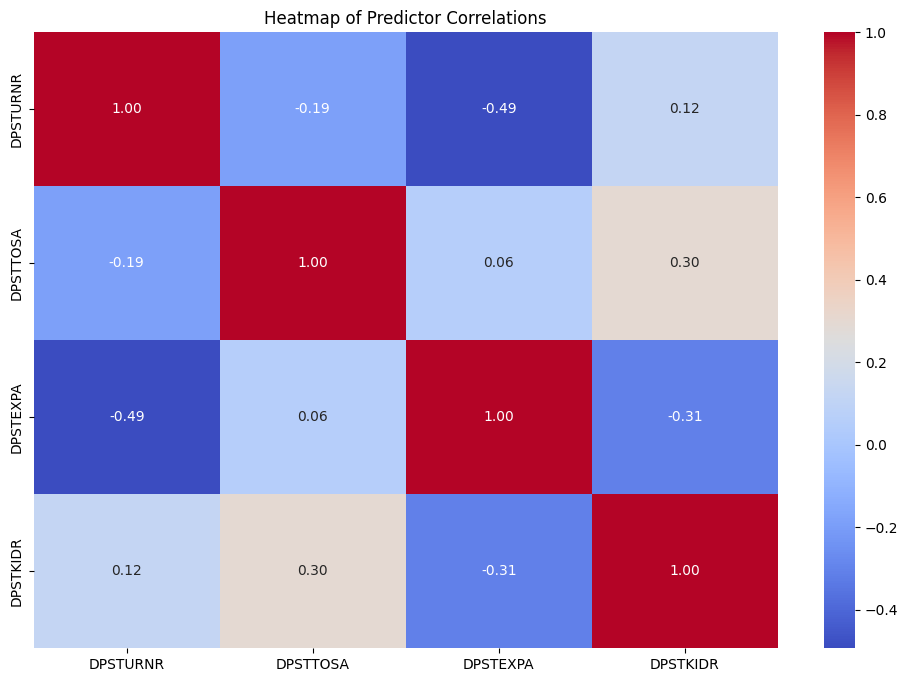

In [51]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure corr_matrix is numeric before plotting
corr_matrix_numeric = corr_matrix.apply(pd.to_numeric, errors='coerce')

plt.figure(figsize=(12,8))
sns.heatmap(corr_matrix_numeric, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Heatmap of Predictor Correlations')
plt.show()

# VIF
# Please define 'predictors' (e.g., predictors = df_turnover[cols]) before running this part.
# X_const = sm.add_constant(predictors)

# vif_data = pd.DataFrame()
# vif_data['Variable'] = X_const.columns
# vif_data['VIF'] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]

# print(vif_data.sort_values('VIF', ascending=False))